In [ ]:
!pip  install tensorflow

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
import os
import kagglehub
path = kagglehub.dataset_download("tombackert/brain-tumor-mri-data")
print(path)

Using Colab cache for faster access to the 'brain-tumor-mri-data' dataset.
/kaggle/input/brain-tumor-mri-data


In [ ]:
for root, folders, files in os.walk(path):
  print(root)

/kaggle/input/brain-tumor-mri-data
/kaggle/input/brain-tumor-mri-data/brain-tumor-mri-dataset
/kaggle/input/brain-tumor-mri-data/brain-tumor-mri-dataset/pituitary
/kaggle/input/brain-tumor-mri-data/brain-tumor-mri-dataset/notumor
/kaggle/input/brain-tumor-mri-data/brain-tumor-mri-dataset/meningioma
/kaggle/input/brain-tumor-mri-data/brain-tumor-mri-dataset/glioma


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32

In [ ]:
datagen = ImageDataGenerator(
    rescale= 1./255,
    validation_split=0.2)

In [ ]:
train_generator = datagen.flow_from_directory(
    path+  "/brain-tumor-mri-dataset",
    target_size = (IMG_SIZE,IMG_SIZE),
    batch_size = BATCH_SIZE,
    class_mode = 'categorical',
    subset = 'training'
)

Found 5723 images belonging to 4 classes.


In [ ]:
validation_generator = datagen.flow_from_directory(
    path+  "/brain-tumor-mri-dataset",
    target_size = (IMG_SIZE,IMG_SIZE),
    batch_size = BATCH_SIZE,
    class_mode = 'categorical',
    subset = 'validation'
)

Found 1430 images belonging to 4 classes.


In [ ]:
print(train_generator.class_indices)

{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [ ]:
model = keras.Sequential([
    layers.Conv2D(32,(3,3),activation='relu',input_shape=(IMG_SIZE,IMG_SIZE,3)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64,(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(128,(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(128,activation='relu'),
    layers.Dense(4,activation='softmax')
])

In [ ]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [ ]:
model.fit(train_generator,epochs=5,validation_data=validation_generator, batch_size= BATCH_SIZE)

Epoch 1/5
179/179 ━━━━━━━━━━━━━━━━━━━━ 729s 4s/step - accuracy: 0.7473 - loss: 0.6132 - val_accuracy: 0.8538 - val_loss: 0.3879
Epoch 2/5
179/179 ━━━━━━━━━━━━━━━━━━━━ 723s 4s/step - accuracy: 0.9112 - loss: 0.2372 - val_accuracy: 0.8979 - val_loss: 0.2910
Epoch 3/5
179/179 ━━━━━━━━━━━━━━━━━━━━ 725s 4s/step - accuracy: 0.9568 - loss: 0.1200 - val_accuracy: 0.8888 - val_loss: 0.3431
Epoch 4/5
179/179 ━━━━━━━━━━━━━━━━━━━━ 727s 4s/step - accuracy: 0.9817 - loss: 0.0552 - val_accuracy: 0.9280 - val_loss: 0.2445
Epoch 5/5
179/179 ━━━━━━━━━━━━━━━━━━━━ 725s 4s/step - accuracy: 0.9927 - loss: 0.0260 - val_accuracy: 0.9357 - val_loss: 0.3150


In [ ]:
model.save("Braintumor_multi.h5")

In [ ]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import numpy as np
model = load_model('Braintumor_multi.h5')
print("model loaded")

model loaded


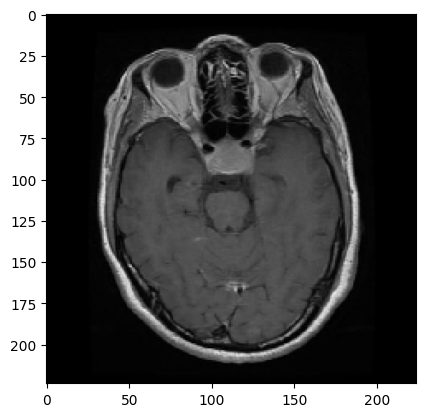

In [ ]:
#load and veiw the test image
test_image_path = "/content/img2.jpeg"
img = image.load_img(test_image_path, target_size=(IMG_SIZE, IMG_SIZE))
plt.imshow(img)
plt.axis()
plt.show()

In [ ]:
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array /= 255.

In [ ]:
predictions = model.predict(img_array)
print(predictions)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
[[2.1845876e-08 6.4774293e-05 6.3696660e-08 9.9993515e-01]]


In [ ]:
class_names = train_generator.class_indices
print(class_names)

{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [ ]:
class_names = list(train_generator.class_indices.keys())
class_names

['glioma', 'meningioma', 'notumor', 'pituitary']

In [ ]:
final_ind = np.argmax(predictions[0])
print(final_ind)


3


In [ ]:
print(class_names[final_ind])

pituitary
